# Experimental: cross-section in height from pressure-level data, with orography

**This is an experimental example.** It reproduces the Metview gallery example [Cross Section in Height for Pressure Level Data with Orography](https://metview.readthedocs.io/en/latest/gen_files/gallery/cross_section_height_pl_orog.html) with earthkit-geo, [earthkit-meteo](https://earthkit-meteo.readthedocs.io), xarray and earthkit-plots. The temperature, which is given on pressure levels, is shown along a line in height above sea level, between 0 and 3000 m, and the orography is drawn as a black area. The horizontal part (the line and the regridding onto it) uses the new `earthkit.geo.polyline` module, whose interface may still change. The vertical computations, the geometric height of the pressure levels and the interpolation from pressure levels to height levels, use `earthkit.meteo.vertical`.

The notebook reads a GRIB file. It contains forecast data of 2020-08-22 00 UTC. 

To make this notebook work [earthkit-data](https://earthkit-data.readthedocs.io), [earthkit-meteo](https://earthkit-meteo.readthedocs.io), [earthkit-plots](https://earthkit-plots.readthedocs.io) and xarray have to be installed.

## Imports

In [1]:
import earthkit.data as ekd
import earthkit.geo as ekg
import earthkit.plots as ekp
import numpy as np
import xarray as xr
from earthkit.geo.distance import haversine_distance
from earthkit.geo.polyline import sample_polyline
from earthkit.meteo import vertical

## Load the data

The file contains the temperature `t` and the geopotential `z` on the pressure levels 1000, 925, 850, 700, 400, 500 and 300 hPa (the order of the levels in the file is not monotonic: 400 comes before 500), for the forecast step of 12 h, and the surface geopotential `z` from the analysis (step 0). It is a GRIB1 file on a regular 0.5° latitude-longitude grid over the area 40–51°N, 93–84°W. Here is a short listing of the first fields.

In [2]:
ds = ekd.from_source("sample", "xs_pl_orog.grib").to_fieldlist()
print(len(ds), "fields")
ds[:6].ls()

xs_pl_orog.grib:   0%|          | 0.00/15.8k [00:00<?, ?B/s]

15 fields


,parameter.variable,time.valid_datetime,time.base_datetime,time.step,vertical.level,vertical.level_type,ensemble.member,geography.grid_type
0,t,2020-08-22 12:00:00,2020-08-22,0 days 12:00:00,1000,pressure,0,regular_ll
1,z,2020-08-22 12:00:00,2020-08-22,0 days 12:00:00,1000,pressure,0,regular_ll
2,t,2020-08-22 12:00:00,2020-08-22,0 days 12:00:00,925,pressure,0,regular_ll
3,z,2020-08-22 12:00:00,2020-08-22,0 days 12:00:00,925,pressure,0,regular_ll
4,t,2020-08-22 12:00:00,2020-08-22,0 days 12:00:00,850,pressure,0,regular_ll
5,z,2020-08-22 12:00:00,2020-08-22,0 days 12:00:00,850,pressure,0,regular_ll


## Select the temperature, the geopotential and the surface geopotential

We select `t` and `z` on the pressure levels, which gives 7 fields each, and `z` at the surface, which gives a single field. The geopotential is in m²/s². The cell prints the pressure levels of the fields in the order they have in the file.

In [3]:
t = ds.sel({"parameter.variable": "t", "vertical.level_type": "pressure"})
z = ds.sel({"parameter.variable": "z", "vertical.level_type": "pressure"})
zs = ds.sel({"parameter.variable": "z", "vertical.level_type": "surface"})

print(len(t), "t fields, levels (hPa):", [f.get("vertical.level") for f in t])
print(len(z), "z fields, levels (hPa):", [f.get("vertical.level") for f in z])
print(len(zs), "surface z field")

7 t fields, levels (hPa): [1000, 925, 850, 700, 400, 500, 300]
7 z fields, levels (hPa): [1000, 925, 850, 700, 400, 500, 300]
1 surface z field


## Define the line

[sample_polyline()](https://earthkit-geo.readthedocs.io) returns the latitudes and longitudes of 200 points along the line from (50.21°N, 91.82°W) to (40.82°N, 84.71°W), which is the line of the Metview example. We use `method="linear"`: the points are evenly spaced in latitude and longitude, i.e. they lie on a straight line in a plain latitude-longitude map, as in Metview. This is not the great circle, which is the default.

In [4]:
lats, lons = sample_polyline([50.21, 40.82], [-91.82, -84.71], n=200, method="linear")
print(lats.shape, (lats[0], lons[0]), (lats[-1], lons[-1]))

(200,) (np.float64(50.21), np.float64(-91.82)) (np.float64(40.82), np.float64(-84.71))


## Regrid onto the line

The temperature, the geopotential and the surface geopotential are regridded onto the 200 points of the line, which are given as an unstructured target grid. The default linear interpolation is used. The result is a fieldlist with one field of 200 values for each field of the input. MIR may print some `GridUnknownError` and `ECCODES` lines during this step (e.g. about an unknown grid or an unstructured grid in a GRIB edition 1 message), they come from the C libraries and do not stop the regridding.

In [5]:
out_grid = {"latitudes": lats.tolist(), "longitudes": lons.tolist()}

t_line = ekg.regrid(t, out_grid=out_grid)
z_line = ekg.regrid(z, out_grid=out_grid)
zs_line = ekg.regrid(zs, out_grid=out_grid)
print(len(t_line), "t fields, shape of the values:", t_line[0].values.shape)
print(len(z_line), "z fields, shape of the values:", z_line[0].values.shape)
print(len(zs_line), "surface z field, shape of the values:", zs_line[0].values.shape)

7 t fields, shape of the values: (200,)
7 z fields, shape of the values: (200,)
1 surface z field, shape of the values: (200,)


ECCODES WARNING grib_util_set_spec_: 'unstructured_grid' specified but input is GRIB edition 1. Output must be a higher edition!
ECCODES WARNING grib_util_set_spec_: 'unstructured_grid' specified but input is GRIB edition 1. Output must be a higher edition!
ECCODES WARNING grib_util_set_spec_: 'unstructured_grid' specified but input is GRIB edition 1. Output must be a higher edition!
ECCODES WARNING grib_util_set_spec_: 'unstructured_grid' specified but input is GRIB edition 1. Output must be a higher edition!
ECCODES WARNING grib_util_set_spec_: 'unstructured_grid' specified but input is GRIB edition 1. Output must be a higher edition!
ECCODES WARNING grib_util_set_spec_: 'unstructured_grid' specified but input is GRIB edition 1. Output must be a higher edition!
ECCODES WARNING grib_util_set_spec_: 'unstructured_grid' specified but input is GRIB edition 1. Output must be a higher edition!
ECCODES WARNING grib_util_set_spec_: 'unstructured_grid' specified but input is GRIB edition 1. O

## Sort the levels by pressure

The vertical interpolation needs levels which are monotonic in pressure, but the levels of the file are not (400 hPa is before 500 hPa). We sort the levels by decreasing pressure, from 1000 to 300 hPa, and sort the temperature and the geopotential each into this same decreasing-pressure order. The cell asserts that the pressure levels of `t` and `z` are the same and that they are monotonic. The arrays have the shape (level, point).

In [6]:
p_t = np.array([f.get("vertical.level") for f in t_line])
p_z = np.array([f.get("vertical.level") for f in z_line])
order = np.argsort(p_t)[::-1]  # decreasing pressure

levels = p_t[order]
T = np.stack([f.values for f in t_line])[order]  # K, (level, point)
Z = np.stack([f.values for f in z_line])[np.argsort(p_z)[::-1]]  # m2/s2, (level, point)
ZS = zs_line[0].values  # m2/s2, (point)

assert np.array_equal(np.sort(p_t), np.sort(p_z)), "t and z must be on the same levels"
assert np.all(np.diff(levels) < 0), "the pressure levels must be monotonic"
print("levels (hPa):", levels.tolist())
print(T.shape, Z.shape, ZS.shape)

levels (hPa): [1000, 925, 850, 700, 500, 400, 300]
(7, 200) (7, 200) (200,)


## Compute the heights

[geometric_height_from_geopotential()](https://earthkit-meteo.readthedocs.io) of `earthkit.meteo.vertical` converts the geopotential to geometric height in m. It gives the height `H` of each pressure level at each point of the line, and the height `HS` of the surface, which is the orography. The cell prints the range of the height of the 1000 hPa level and of the orography. The 1000 hPa level is below the ground everywhere on this line, because the orography is higher than the height of this level.

In [7]:
H = vertical.geometric_height_from_geopotential(Z)  # m, (level, point)
HS = vertical.geometric_height_from_geopotential(ZS)  # m, (point)

print(f"height of the 1000 hPa level: {H[0].min():.0f} to {H[0].max():.0f} m")
print(f"orography: {HS.min():.0f} to {HS.max():.0f} m")
assert levels[0] == 1000 and np.all(H[0] < HS), "1000 hPa is expected to be below ground on the line"

height of the 1000 hPa level: 82 to 125 m
orography: 173 to 532 m


## Interpolate the temperature to height levels

The temperature is converted from K to °C by subtracting 273.15 (Metview uses 273.16, the difference of 0.01 °C is not visible). [interpolate_pressure_to_height_levels()](https://earthkit-meteo.readthedocs.io) then interpolates it linearly from the pressure levels to the target heights 0, 20, 40, …, 3000 m above sea level, at each point of the line. The heights are geometric (`h_type="geometric"`) and given above sea level (`h_reference="sea"`). The geopotential `Z` of the pressure levels gives the heights of the levels, and `vertical_dim=0` says that the first axis of the arrays is the vertical one. The result has the shape (height, point).

In [8]:
target_h = np.arange(0, 3001, 20)  # m above sea level
t_celsius = T - 273.15
t_height = vertical.interpolate_pressure_to_height_levels(
    t_celsius,
    target_h,
    Z,
    zs=ZS,
    h_type="geometric",
    h_reference="sea",
    interpolation="linear",
    vertical_dim=0,
)
print(t_height.shape, "NaNs:", int(np.isnan(t_height).sum()))

(151, 200) NaNs: 1107


## Check the values above the ground

With `h_reference="sea"` the surface geopotential `zs` is not used by the interpolation, so the values below the ground are not set to missing by it. Below the ground they may be finite or `NaN`, depending on the heights of the levels, and in both cases they are hidden by the orography, which is drawn on top of the plot. What matters is that there are no missing values above the ground. The cell below counts the missing values below and above the ground (a target height above the ground is a height above `HS`), and asserts that there are none above the ground.

In [9]:
above_ground = target_h[:, np.newaxis] > HS[np.newaxis, :]
nan = np.isnan(t_height)
print("NaNs below the ground:", int((nan & ~above_ground).sum()), "of", int((~above_ground).sum()), "values")
print("NaNs above the ground:", int((nan & above_ground).sum()), "of", int(above_ground.sum()), "values")
assert not nan[above_ground].any(), "there must be no NaN above the ground"
t_above = t_height[above_ground]
print(f"temperature above the ground: {t_above.min():.1f} to {t_above.max():.1f} °C")

NaNs below the ground: 1107 of 3144 values
NaNs above the ground: 0 of 27056 values
temperature above the ground: 4.7 to 23.9 °C


## Build an Xarray Dataset

We build a Dataset with the temperature `t` (°C) on the dimensions `height` (m) and `distance` (km), and the orography on `distance` only. The distance is the cumulative length of the path along the sampled points. It is the sum of the haversine distances (in metres, so we divide by 1000) between consecutive points. The latitudes and longitudes of the points are stored as auxiliary coordinates of `distance`.

In [10]:
# cumulative path length along the sampled points, in km
step_length = np.array([
    haversine_distance((lats[i], lons[i]), (lats[i + 1], lons[i + 1])) for i in range(len(lats) - 1)
])
distance = np.concatenate([[0.0], np.cumsum(step_length)]) / 1000

xs = xr.Dataset(
    {
        "t": (
            ("height", "distance"),
            t_height,
            {"units": "degC", "long_name": "Temperature"},
        ),
        "orography": (
            ("distance",),
            HS,
            {"units": "m", "long_name": "Orography"},
        ),
    },
    coords={
        "height": ("height", target_h, {"units": "m"}),
        "distance": ("distance", distance, {"units": "km"}),
        "latitude": ("distance", lats, {"units": "degrees_north"}),
        "longitude": ("distance", lons, {"units": "degrees_east"}),
    },
)
xs

<xarray.Dataset> Size: 249kB
Dimensions:    (height: 151, distance: 200)
Coordinates:
  * height     (height) int64 1kB 0 20 40 60 80 100 ... 2920 2940 2960 2980 3000
  * distance   (distance) float64 2kB 0.0 5.831 11.66 ... 1.176e+03 1.182e+03
    latitude   (distance) float64 2kB 50.21 50.16 50.12 ... 40.91 40.87 40.82
    longitude  (distance) float64 2kB -91.82 -91.78 -91.75 ... -84.75 -84.71
Data variables:
    t          (height, distance) float64 242kB nan nan nan ... 6.583 6.598
    orography  (distance) float64 2kB 384.9 387.7 390.5 ... 237.7 239.6 241.6

## Plot the cross-section

We plot the filled contours of temperature with a non-map earthkit-plots `Subplot`, as in the Metview example, which has no map. The levels go from 4 to 25 °C every 1 °C. The colour map is the matplotlib `RdYlBu_r`, from blue through pale yellow to red. This is an approximate alternative to the Metview palette (pale blue, olive, yellow, orange and red), whose hues are noticeably different. Contour lines every 1 °C are drawn in charcoal, with a label every 2 °C. The colour bar is added with the `legend()` method of the figure. The orography is added with `fill_between()` and drawn in charcoal from the surface height down to 0 m, on top of the temperature. The vertical axis goes from 0 to 3000 m.

The 7 ticks of the horizontal axis are where the line crosses the whole longitudes 91°W, 90°W, …, 85°W, as in Metview. Their distance and latitude are found by linear interpolation along the sampled points, because they are not at sampled points. The labels have the latitude with up to 2 decimals (a trailing zero is dropped, as in Metview: "41.2°N/85°W") and the longitude in whole degrees.

Two details need explanation:

- `resample=False` is needed for `contourf()` and `contour()`. By default earthkit-plots resamples the data onto a 1000 × 1000 latitude-longitude grid, which is wrong for a distance-height section.
- The axis limits, the ticks and the labels are set with matplotlib calls on the axis `.ax` of the subplot, because earthkit-plots has no dedicated option for them.

['49.13°N/91°W', '47.81°N/90°W', '46.49°N/89°W', '45.17°N/88°W', '43.84°N/87°W', '42.52°N/86°W', '41.2°N/85°W']


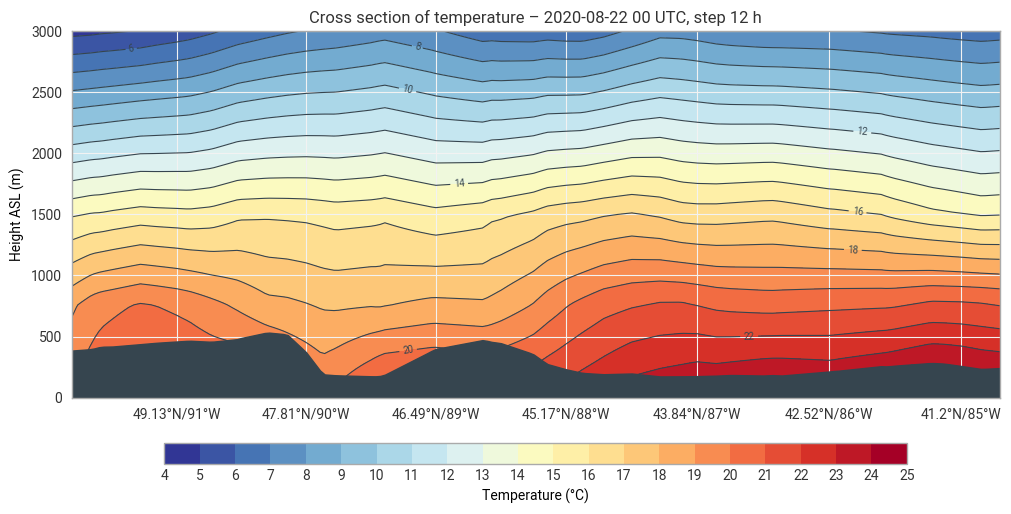

In [11]:
levels_t = list(range(4, 26))

# 7 ticks where the line crosses the longitudes 91W ... 85W (lons increase along the line)
tick_lons = np.arange(-91, -84)
tick_distance = np.interp(tick_lons, lons, distance)
tick_lats = np.interp(tick_lons, lons, lats)
tick_labels = [f"{round(lat, 2):g}°N/{abs(lon)}°W" for lat, lon in zip(tick_lats, tick_lons)]
print(tick_labels)

chart = ekp.Subplot(figsize=(10, 5))
chart.contourf(
    xs["t"],
    x="distance",
    y="height",
    style=ekp.styles.Style(levels=levels_t, colors="RdYlBu_r", ticks=levels_t),
    resample=False,
)
chart.contour(
    xs["t"],
    x="distance",
    y="height",
    style=ekp.styles.Contour(
        levels=levels_t,
        colors="#36454f",
        linewidths=0.8,
        labels=True,
        label_kwargs={"label_frequency": 2, "label_fmt": "%g"},
        legend_style=None,  # no second colour bar for the lines
    ),
    resample=False,
)
chart.figure.legend(label="Temperature (°C)")
# orography: charcoal polygon from the surface height down to 0 m, drawn on top
chart.fill_between(xs["orography"], 0, x=xs["distance"], color="#36454f", alpha=1)

ax = chart.ax
ax.set_xlim(distance[0], distance[-1])
ax.set_ylim(0, 3000)
ax.set_xticks(tick_distance)
ax.set_xticklabels(tick_labels)
ax.set_ylabel("Height ASL (m)")
ax.set_title("Cross section of temperature – 2020-08-22 00 UTC, step 12 h")

chart.show()